AdaBoost will use Sex, culmen_length, culmen_depth, flipper_length, and body_mass to predict Species.

** Since Species and Island overlap a lot, we will leave Island out of the Features list.

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

1. CLEANING DATA

In [2]:
#Load in the dataset
penguin_size = pd.read_csv('/content/penguins_size.csv')

#drop columns with NaN
penguin_size_cleaned = penguin_size.dropna()

#checking the distinct values
for col in penguin_size_cleaned.select_dtypes(include="object"):
    print(col, penguin_size_cleaned[col].value_counts(dropna=False), "\n")

species species
Adelie       146
Gentoo       120
Chinstrap     68
Name: count, dtype: int64 

island island
Biscoe       164
Dream        123
Torgersen     47
Name: count, dtype: int64 

sex sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64 



In [3]:
#remove the invalid value for sex
penguin_size_cleaned = penguin_size_cleaned[penguin_size_cleaned["sex"].isin(["MALE", "FEMALE"])]

penguin_size_cleaned.head()

penguin_size_cleaned.to_csv('cleaned_penguin_size_data_regression.csv', index=False)

2. FEATURE PREPARATION AND SELECTION

a. Encoding

In [6]:
# One-hot encode Sex
onehot_encoder = OneHotEncoder(sparse_output=False)
sex_encoded = onehot_encoder.fit_transform(penguin_size_cleaned[["sex"]])
sex_df = pd.DataFrame(
    sex_encoded,
    columns=onehot_encoder.get_feature_names_out(["sex"]),
    index=penguin_size_cleaned.index,
)

b. Feature Selection

In [7]:
# Features: numeric columns + encoded sex
numeric_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
X = pd.concat([penguin_size_cleaned[numeric_cols], sex_df], axis=1)

# Target:
y = penguin_size_cleaned["species"]

c. Spliting into train, test, and validation

In [10]:
from sklearn.model_selection import train_test_split

# Split off 15% for the final test set (85% remains for train + val)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# Split the remaining 85% into train (70% of total) and validation (15% of total)
# Math: 0.15 / 0.85 ≈ 0.1765
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42
)

3. FIT AND TUNE THE MODEL

In [12]:
#fit and tune the model on different n_estimator and learning rate
results = []
for lr in [0.01, 0.1, 0.5, 1.0]:
    for n in [10, 25, 50, 100, 200]:
        model = AdaBoostClassifier(n_estimators=n, learning_rate=lr, random_state=42)
        model.fit(X_train, y_train)
        results.append({
            "learning_rate": lr,
            "n_estimators": n,
            "train_acc": model.score(X_train, y_train),
            "val_acc": model.score(X_val, y_val),
        })

results_df = pd.DataFrame(results).sort_values("val_acc", ascending=False)
print(results_df.head())

    learning_rate  n_estimators  train_acc  val_acc
19            1.0           200   0.991416     1.00
18            1.0           100   0.991416     1.00
17            1.0            50   0.991416     1.00
16            1.0            25   0.987124     1.00
13            0.5           100   0.974249     0.98


From tuning, it seems like the model performs the best with n_estimator = 200, 100 or 50, and learning_rate is 1

Since the performance is the same, I will choose n_estimator = 50 and learning_rate=1, so the compuing power is less.

4. PREDICT

Accuracy score: 0.9600


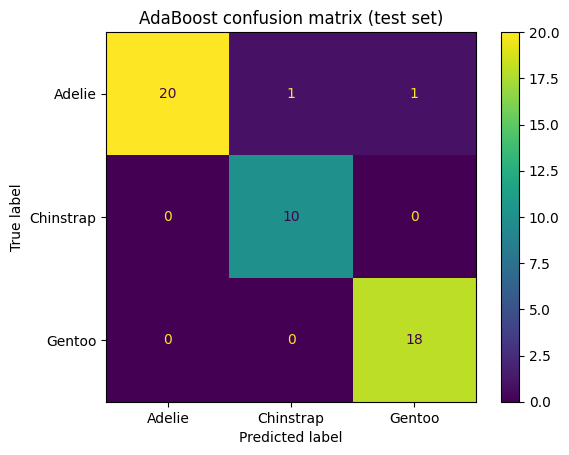

In [14]:
model_final = AdaBoostClassifier(n_estimators=50, learning_rate=1, random_state=42)
model_final.fit(X_temp, y_temp)
#predicting
y_pred = model_final.predict(X_test)

#evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy score: {accuracy:.4f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("AdaBoost confusion matrix (test set)")
plt.show()

5. COMPARE WITH DECISION TREE

Decision tree accuracy: 0.9200


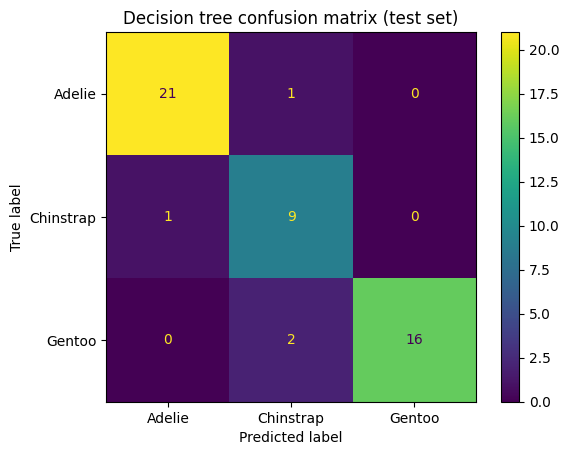

In [15]:
#Fit Decision Tree
from sklearn.tree import DecisionTreeClassifier

#Using the same tree setting as in the last module
tree_gini = DecisionTreeClassifier(criterion="gini", random_state=42, max_depth=3, min_samples_leaf=5)
tree_gini.fit(X_temp, y_temp)

y_pred_tree = tree_gini.predict(X_test)

#Evalute tree
accuracy_tree = accuracy_score(y_test, y_pred_tree)
print(f"Decision tree accuracy: {accuracy_tree:.4f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree)
plt.title("Decision tree confusion matrix (test set)")
plt.show()

6. RESULT INTERPRETATION

a. Tuning
- With learning_rate = 1.0, validation accuracy reached 100% by 25 rounds and stayed there. Lower learning rates improved more slowly. I chose n_estimators = 50 and learning_rate = 1.0, the simplest setting at which both training and validation accuracy had leveled off.

b. Accuracy
- On the test set, AdaBoost achieved 96% accuracy (48 of 50 correct). This is slightly below its 100% validation accuracy, which is expected with only about 50 penguins in each set.

c. Confusion matrix
- Both errors were Adelie penguins: one was predicted as a Chinstrap and one as a Gentoo. All Chinstraps and Gentoos were classified correctly.

d. Comparison with the decision tree
- AdaBoost outperformed the Part 3 decision tree (96% vs. 92%, i.e., 48 vs. 46 correct), and the tree made errors in all three species. A likely reason is that the tree is a single model limited to depth 3, while AdaBoost combines 50 stumps with a weighted vote. Because each round gives more weight to penguins that earlier stumps misclassified, later stumps focus on the hard cases near species boundaries. The gap is only 2 penguins on a small test set, so AdaBoost's advantage is real but modest.